# 16.71 - Train-only spacing add-on quality filter

## Purpose
Create two reproducible candidate packages from the 119-image `teeth_gap` **training partition**: (A) remove only 26 predeclared out-of-scope/composite candidates (expected 93 images / 165 boxes), and (B) apply the same screen plus deterministic one-per-strict-duplicate-component selection (expected 60 images / 104 boxes).

This is a data-preparation experiment, not clinical relabeling. The earlier all-data add-on is already submitted as notebook 16.67 and must remain unchanged. These candidates are staged locally only; do not upload or train them until 16.67 is collected and its fixed-validation comparison supports a follow-up. Project validation/test membership is not touched. External source validation/test files are not included.

## 1. Freeze and verify the reviewed source evidence

The inputs are the immutable train-only derivative, its source manifest, the filename-keyed visual triage decisions, and strict duplicate components. Verify each checksum and one-to-one row join before selecting anything.

In [1]:
from pathlib import Path
import hashlib, json, shutil
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / "notebooks").is_dir() and (ROOT / "data").is_dir(), ROOT
SOURCE = ROOT / "data/processed/teeth_gap_v1_screened2"
REPORT = ROOT / "docs/reports/alignment/teeth_gap_v1"
OUT_ROOT = ROOT / ".venv/work/kaggle/spacing_addon_screened_candidates"
EXPECTED_MANIFEST_SHA = "9c413bc2f2e811c22fb3e31f46f7ce584840fca75c5d6b99372ce17f1cb94036"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

manifest_path = REPORT / "manifest.csv"
triage_path = REPORT / "image_level_review_named/train_image_triage_v1.csv"
components_path = REPORT / "strict_duplicate_components_train.csv"
assert sha256_file(manifest_path) == EXPECTED_MANIFEST_SHA
manifest_all = pd.read_csv(manifest_path)
triage = pd.read_csv(triage_path)
components = pd.read_csv(components_path)
assert len(manifest_all) == 141 and manifest_all.output_image.is_unique
manifest = manifest_all[manifest_all.split.eq("train")].copy()
assert len(manifest) == 119 and manifest.output_image.is_unique
assert len(triage) == 119 and triage.output_image.is_unique
assert len(components) == 119 and components.output_image.is_unique
assert set(manifest.output_image) == set(triage.output_image) == set(components.output_image)
assert set(manifest.split) == {"train"} and set(components.split) == {"train"}
print({"source_train_images": len(manifest), "source_train_boxes": int(manifest.boxes.sum()),
       "source_manifest_sha256": EXPECTED_MANIFEST_SHA, "external_validation_used": False,
       "source_test_opened": False})

{'source_train_images': 119, 'source_train_boxes': 216, 'source_manifest_sha256': '9c413bc2f2e811c22fb3e31f46f7ce584840fca75c5d6b99372ce17f1cb94036', 'external_validation_used': False, 'source_test_opened': False}


## 2. Apply the frozen train-only decision rule

Keep every `retain_candidate` and `manual_review` row for the screened candidate; exclude only the predeclared `exclude_candidate` rows. The stricter variant selects one lexicographically smallest filename per strict duplicate component after the same exclusion. This deterministic tie-break is a deduplication rule, not a quality ranking.

In [2]:
joined = manifest.merge(triage[["output_image", "visual_triage", "reason"]], on="output_image", validate="one_to_one")
joined = joined.merge(components[["output_image", "strict_component_id"]], on="output_image", validate="one_to_one")
assert joined.image_sha256.is_unique, "Unexpected repeated content in source rows"
counts = joined.visual_triage.value_counts().to_dict()
assert counts == {"manual_review": 84, "exclude_candidate": 26, "retain_candidate": 9}, counts
screened = joined[joined.visual_triage.ne("exclude_candidate")].copy()
dedup = (screened.sort_values(["strict_component_id", "output_image"])
         .drop_duplicates("strict_component_id", keep="first").copy())
assert (len(screened), int(screened.boxes.sum())) == (93, 165)
assert (len(dedup), int(dedup.boxes.sum())) == (60, 104)
assert dedup.strict_component_id.is_unique
summary = pd.DataFrame([
    {"candidate": "screened_93", "images": len(screened), "boxes": int(screened.boxes.sum()),
     "positive_images": len(screened), "rule": "exclude 26 predeclared exclude_candidate rows"},
    {"candidate": "screened_dedup_60", "images": len(dedup), "boxes": int(dedup.boxes.sum()),
     "positive_images": len(dedup), "rule": "same screen + one filename per strict component"},
])
display(summary)

,candidate,images,boxes,positive_images,rule
0,screened_93,93,165,93,exclude 26 predeclared exclude_candidate rows
1,screened_dedup_60,60,104,60,same screen + one filename per strict component


## 3. Build allowlisted, train-only packages

Each package contains only selected images/labels, the selection manifest, a one-class mapping, attribution and a machine-readable receipt. It deliberately has no `valid` or `test` directory. All original source evidence remains untouched.

In [3]:
def build_package(name, selected, rule):
    out = OUT_ROOT / name
    resolved_root = OUT_ROOT.resolve()
    assert out.resolve().is_relative_to(resolved_root), out
    if out.exists():
        shutil.rmtree(out)
    (out / "train/images").mkdir(parents=True)
    (out / "train/labels").mkdir(parents=True)
    rows = []
    for row in selected.sort_values("output_image").itertuples(index=False):
        image_src = SOURCE / "train/images" / row.output_image
        label_src = SOURCE / "train/labels" / (Path(row.output_image).stem + ".txt")
        assert image_src.is_file() and label_src.is_file()
        assert sha256_file(image_src) == row.image_sha256
        assert sha256_file(label_src) == row.label_sha256
        label_lines = [line for line in label_src.read_text(encoding="utf-8").splitlines() if line.strip()]
        assert len(label_lines) == int(row.boxes)
        assert all(line.split()[0] == "0" for line in label_lines)
        for line in label_lines:
            vals = [float(x) for x in line.split()[1:]]
            assert len(vals) == 4 and all(0 <= x <= 1 for x in vals)
        shutil.copy2(image_src, out / "train/images" / row.output_image)
        out_label = out / "train/labels" / (Path(row.output_image).stem + ".txt")
        shutil.copy2(label_src, out_label)
        rows.append({"output_image": row.output_image, "boxes": int(row.boxes),
                     "image_sha256": row.image_sha256, "label_sha256": row.label_sha256,
                     "visual_triage": row.visual_triage, "strict_component_id": row.strict_component_id,
                     "selection_rule": rule})
    pd.DataFrame(rows).to_csv(out / "manifest.csv", index=False)
    (out / "data.yaml").write_text("path: .\ntrain: train/images\nnames:\n  0: spacing\n", encoding="utf-8")
    slug = "spacing-addon-screened-93-v1" if name.endswith("93_v1") else "spacing-addon-screened-dedup-60-v1"
    kaggle_metadata = {"title": name.replace("_", " ").title(),
        "id": f"hngphc73/{slug}", "licenses": [{"name": "CC-BY-4.0"}],
        "keywords": ["dentistry", "spacing", "object-detection", "train-only"]}
    (out / "dataset-metadata.json").write_text(json.dumps(kaggle_metadata, indent=2), encoding="utf-8")
    (out / "README.md").write_text(
        "# Teeth-gap screened train-only candidate\n\n"
        "Source: Roboflow Universe `random-dznie/teeth_gap`, v1, declared CC BY 4.0.\n\n"
        f"Selection: {rule}.\n\n"
        "These are AI-assisted image/task-compatibility decisions, not clinical adjudications. "
        "Manual-review rows remain uncertain. This package contains no source validation or test items; "
        "the project validation remains the sole primary comparison cohort. Patient independence is unverified.\n\n"
        "Attribution: random-dznie, `teeth_gap` v1, CC BY 4.0. "
        "Source: https://universe.roboflow.com/random-dznie/teeth_gap/dataset/1\n", encoding="utf-8")
    receipt = {"candidate": name, "selection_rule": rule, "source_manifest_sha256": EXPECTED_MANIFEST_SHA,
               "images": len(rows), "boxes": int(sum(r["boxes"] for r in rows)),
               "source_validation_included": False, "source_test_included": False,
               "clinical_adjudication": False, "patient_independence_verified": False,
               "source_license_declared": "CC BY 4.0", "files_sha256": {}}
    for path in sorted(out.rglob("*")):
        if path.is_file() and path.name != "package_receipt.json":
            receipt["files_sha256"][path.relative_to(out).as_posix()] = sha256_file(path)
    (out / "package_receipt.json").write_text(json.dumps(receipt, indent=2), encoding="utf-8")
    return out, receipt

OUT_ROOT.mkdir(parents=True, exist_ok=True)
package_93, receipt_93 = build_package("spacing_addon_screened_93_v1", screened,
    "exclude 26 predeclared exclude_candidate train images; retain 84 manual-review rows and 9 retain-candidate rows")
package_60, receipt_60 = build_package("spacing_addon_screened_dedup_60_v1", dedup,
    "same train-only screen, then choose lexicographically smallest filename per strict duplicate component")
display(pd.DataFrame([receipt_93, receipt_60])[["candidate", "images", "boxes", "source_validation_included", "source_test_included"]])
print({"staged_root": str(OUT_ROOT), "upload_or_training_started": False})

,candidate,images,boxes,source_validation_included,source_test_included
0,spacing_addon_screened_93_v1,93,165,False,False
1,spacing_addon_screened_dedup_60_v1,60,104,False,False


{'staged_root': 'C:\\Users\\huynh\\Desktop\\oral-disease\\.venv\\work\\kaggle\\spacing_addon_screened_candidates', 'upload_or_training_started': False}


## 4. Verify package integrity and show representative boxes

Re-open every image/label pair and confirm the strict candidate is a subset of the screened one. The gallery is a deterministic sample from the screen-only package; it does not claim clinical correctness.

,name,images,boxes,manifest_sha256,integrity
0,spacing_addon_screened_93_v1,93,165,672caf0182dd9b2479dcc3f1ef0ec7cc956bff0e02f68c...,passed
1,spacing_addon_screened_dedup_60_v1,60,104,1b57f40a489dae4d136037a4d9a3c7c6cb996b0af977e0...,passed


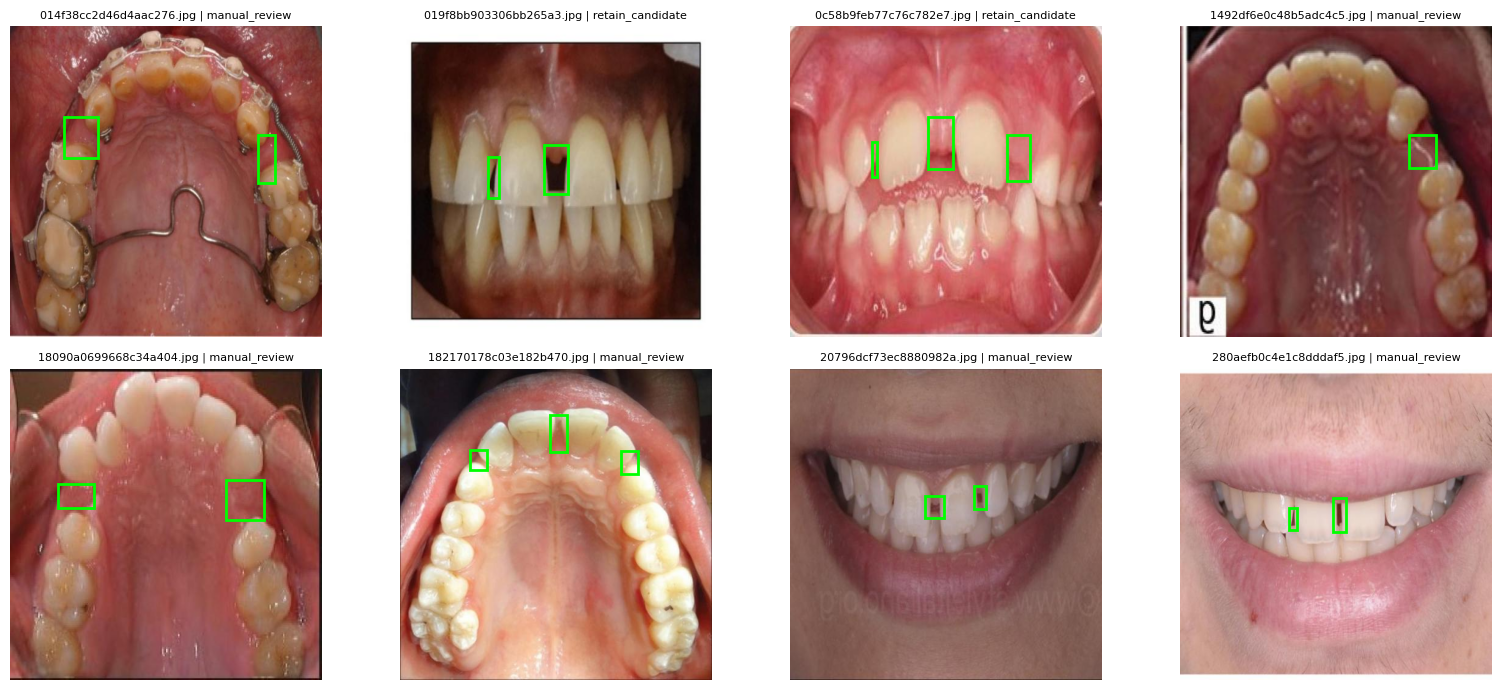

In [4]:
def verify_package(root, expected_images, expected_boxes):
    images = sorted((root / "train/images").glob("*"))
    labels = sorted((root / "train/labels").glob("*.txt"))
    assert len(images) == len(labels) == expected_images
    assert not (root / "valid").exists() and not (root / "test").exists()
    total = 0
    for image in images:
        label = root / "train/labels" / (image.stem + ".txt")
        assert label.is_file()
        with Image.open(image) as im: im.verify()
        total += len([x for x in label.read_text(encoding="utf-8").splitlines() if x.strip()])
    assert total == expected_boxes, (total, expected_boxes)
    receipt = json.loads((root / "package_receipt.json").read_text(encoding="utf-8"))
    for rel, expected in receipt["files_sha256"].items():
        assert sha256_file(root / rel) == expected, rel
    return {"name": root.name, "images": len(images), "boxes": total, "manifest_sha256": sha256_file(root / "manifest.csv"), "integrity": "passed"}

verification = [verify_package(package_93, 93, 165), verify_package(package_60, 60, 104)]
assert set(pd.read_csv(package_60 / "manifest.csv").output_image).issubset(
    set(pd.read_csv(package_93 / "manifest.csv").output_image))
display(pd.DataFrame(verification))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
samples = screened.sort_values("output_image").head(8)
for ax, row in zip(axes.flat, samples.itertuples(index=False)):
    image_path = package_93 / "train/images" / row.output_image
    with Image.open(image_path) as im: ax.imshow(im.convert("RGB"))
    h, w = Image.open(image_path).size[1], Image.open(image_path).size[0]
    label_path = package_93 / "train/labels" / (Path(row.output_image).stem + ".txt")
    for line in label_path.read_text(encoding="utf-8").splitlines():
        _, xc, yc, bw, bh = map(float, line.split())
        x0, y0 = (xc-bw/2)*w, (yc-bh/2)*h
        ax.add_patch(plt.Rectangle((x0,y0), bw*w, bh*h, fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(f"{row.output_image} | {row.visual_triage}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## Decision gate

Notebook 16.67 must be collected first. If its 4x all-data add-on improves both AP50 and AP50-95 on the same locked project validation without a material recall loss, use the 93-image screened package as the next data-quality ablation. If it does not pass, do not spend GPU on the 60-image subset by default; first use the error/data evidence to decide whether a label/view redesign is more defensible. Never choose a candidate by whichever validation score is highest, and keep both fixed validation views unchanged.